# IS 362 — Week 8: Auto MPG Exploratory Data Analysis

**Goal:** Load the UCI Auto MPG dataset directly from the web, clean it reproducibly, and explore relationships with charts.

## 1–3. Load the dataset and name columns
The [UCI Auto MPG dataset](https://archive.ics.uci.edu/dataset/9/auto+mpg) describes fuel efficiency and vehicle characteristics. The dataset documentation lists eight attributes: mpg, cylinders, displacement, horsepower, weight, acceleration, model year, and origin. The raw file also includes a car-name field. The raw dataset has 398 rows. Origin is encoded as 1=USA, 2=Europe, 3=Japan in the original documentation; this assignment specifically requests 1=USA, 2=Asia, 3=Europe, so the assignment mapping is used below.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columns = ["mpg", "cylinders", "displacement", "horsepower", "weight",
           "acceleration", "model_year", "origin", "car_name"]
df = pd.read_fwf(url, names=columns, na_values='?')
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,"""chevrolet chevelle malibu"""
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,"""buick skylark 320"""
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,"""plymouth satellite"""
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,"""amc rebel sst"""
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,"""ford torino"""


## 4–5. Clean horsepower and transform origin
The `?` placeholders are interpreted as missing values on import. We explicitly convert horsepower to numeric, then apply the origin labels **as specified in the assignment**. Note that this differs from the UCI documentation, which identifies 2 as Europe and 3 as Japan.

In [4]:
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["origin"] = df["origin"].map({1: "USA", 2: "Asia", 3: "Europe"})
print(df.info())
print("\nMissing values by column:\n", df.isna().sum())
display(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(2), object(2)
memory usage: 28.1+ KB
None

Missing values by column:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398,398
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,305
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,USA,"""ford pinto"""
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,249,6
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,NaN,NaN
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,NaN,NaN
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,NaN,NaN
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,NaN,NaN
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,NaN,NaN
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,NaN,NaN


## 6. Bar chart: Distribution of cylinders
This chart counts the number of cars with each cylinder count.

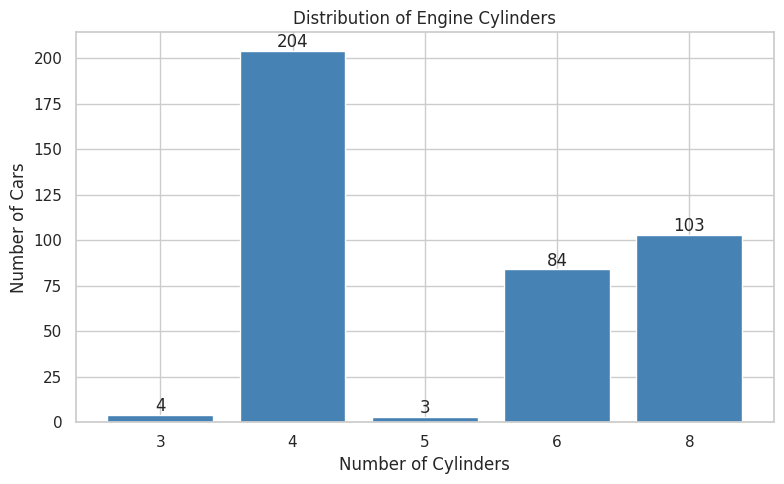

Most common cylinder count: 4


In [5]:
counts = df["cylinders"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(counts.index.astype(str), counts.values, color="steelblue")
ax.set(title="Distribution of Engine Cylinders", xlabel="Number of Cylinders", ylabel="Number of Cars")
for i, value in enumerate(counts.values):
    ax.text(i, value + 2, str(value), ha="center")
plt.tight_layout()
plt.show()
print("Most common cylinder count:", counts.idxmax())

## 7. Scatterplot: Horsepower vs. weight
Each point represents a vehicle with recorded horsepower. Missing horsepower values are excluded only for this plot.

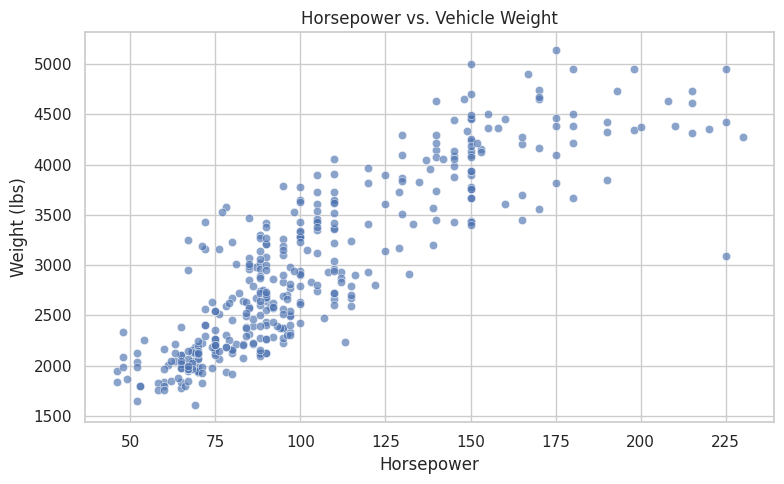

Pearson correlation: 0.865


In [6]:
hp_weight = df.dropna(subset=["horsepower", "weight"])
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=hp_weight, x="horsepower", y="weight", alpha=0.65, ax=ax)
ax.set(title="Horsepower vs. Vehicle Weight", xlabel="Horsepower", ylabel="Weight (lbs)")
plt.tight_layout()
plt.show()
print("Pearson correlation:", round(hp_weight["horsepower"].corr(hp_weight["weight"]), 3))

## 8. Research question: Do cars with more horsepower tend to have lower MPG?
We use a scatterplot with a fitted trend line, plus a correlation coefficient, to investigate whether higher horsepower is associated with lower fuel economy. Correlation does not prove causation.

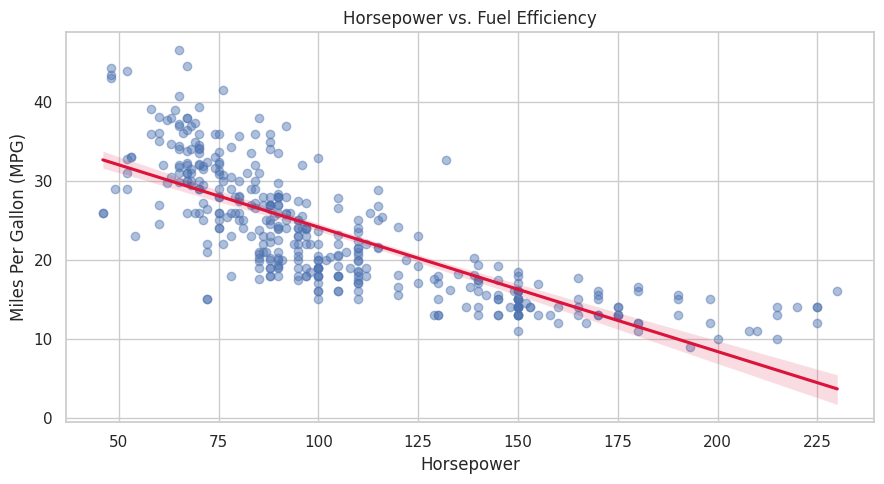

Pearson correlation (horsepower vs MPG): -0.778
Answer: The relationship is negative: cars with greater horsepower generally have lower MPG.


In [7]:
analysis = df.dropna(subset=["horsepower", "mpg"])
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=analysis, x="horsepower", y="mpg",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "crimson"}, ax=ax)
ax.set(title="Horsepower vs. Fuel Efficiency", xlabel="Horsepower", ylabel="Miles Per Gallon (MPG)")
plt.tight_layout()
plt.show()
r = analysis["horsepower"].corr(analysis["mpg"])
print(f"Pearson correlation (horsepower vs MPG): {r:.3f}")
print("Answer: The relationship is negative: cars with greater horsepower generally have lower MPG." if r < 0 else "Answer: This dataset does not show a negative linear relationship.")

## Conclusions
- The cylinder bar chart identifies which engine size categories are most common.
- The horsepower–weight scatterplot shows whether heavier cars generally have more horsepower.
- The horsepower–MPG scatterplot and correlation test whether more powerful cars tend to have lower fuel economy.
- Six records have missing horsepower in the original dataset; retaining them in the main DataFrame avoids discarding information unnecessarily.

**Reproducibility:** Run all cells from top to bottom in Jupyter. The notebook downloads the source file directly, and every cleanup operation is included in code. Requires `pandas`, `numpy`, `matplotlib`, and `seaborn`.

**Source:** [UCI Machine Learning Repository — Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg).